# 13_ROCOv2_Statistical_Analysis

**Purpose:** Formal statistical comparison of the three models — paired
bootstrap confidence intervals and significance tests on Test-final,
plus a per-label paired non-parametric test — the final notebook in this
pipeline.

### Methodology
- **Paired bootstrap resampling** (B=2,000, fixed seed): the same
  resampled sample indices are applied to all three models on each
  iteration (since all three were evaluated on the identical Test-final
  samples in Notebook 08), giving correctly *paired* confidence intervals
  and difference distributions — not independent bootstraps that would
  ignore the shared test set.
  - 95% CI (percentile method) for Macro-F1 and Micro-F1 per model.
  - Pairwise differences (Proposed VLM vs. DenseNet121, Proposed VLM vs.
    BiomedCLIP zero-shot, DenseNet121 vs. BiomedCLIP zero-shot): 95% CI of
    the difference and a two-sided bootstrap p-value. A CI that excludes
    zero is the standard bootstrap significance criterion.
- **Per-label paired Wilcoxon signed-rank test**: per-label F1 (computed
  fresh here, on Test-final) gives exactly 18 paired observations per
  model pair — appropriate for a small-N non-parametric paired test,
  complementing the sample-level bootstrap with a label-level view.
- All metrics/thresholds (0.5, multi-label BCE-trained sigmoid outputs)
  are consistent with every prior notebook's convention.
- **No model is loaded, no inference is re-run.** Reads each model's
  existing predictions, filtered to Test-final.

### Inputs
- `Prepared/Baselines/DenseNet121_Unimodal/densenet121_predictions.csv` (05)
- `Prepared/Baselines/BiomedCLIP_VLM_ZeroShot/biomedclip_predictions.csv` (06)
- `Prepared/Baselines/BiomedCLIP_VLM_Trained/vlm_predictions.csv` (07)
- `Prepared/test_final_prepared.csv` (08), `label_mapping.json`.

### Outputs
Under `Prepared/StatisticalAnalysis/`: bootstrap CI table, pairwise
significance table, per-label Wilcoxon results, forest-plot figure,
config, reproducibility record, manifest.

### Non-goals
No new model training or inference. No modification of any previous
notebook or artifact. This is the last notebook in the pipeline.

In [ ]:
# ============================================================
# CELL 1 — CONFIGURATION, PATHS, AND REPRODUCIBILITY
# ============================================================

import sys
import json
import random
import platform
import warnings
from pathlib import Path

import numpy as np
import pandas as pd

warnings.filterwarnings("ignore")

try:
    from google.colab import drive
    drive.mount("/content/drive", force_remount=False)
    IN_COLAB = True
    print("Google Drive available.")
except ImportError:
    IN_COLAB = False
    print("Not running in Google Colab.")

ROCO_ROOT = Path("/content/drive/MyDrive/ROCOv2")
PREPARED_DIR = ROCO_ROOT / "Prepared"

STATS_DIR = PREPARED_DIR / "StatisticalAnalysis"
FIG_DIR = STATS_DIR / "figures"
for d in [STATS_DIR, FIG_DIR]:
    d.mkdir(parents=True, exist_ok=True)

TEST_FINAL_PREPARED_PATH = PREPARED_DIR / "test_final_prepared.csv"
LABEL_MAPPING_PATH = PREPARED_DIR / "label_mapping.json"

MODEL_REGISTRY = [
    {"name": "densenet121", "display_name": "DenseNet121 (image-only baseline)",
     "predictions_path": PREPARED_DIR / "Baselines" / "DenseNet121_Unimodal" / "densenet121_predictions.csv",
     "prob_suffix": "_prob"},
    {"name": "biomedclip_zeroshot", "display_name": "BiomedCLIP (zero-shot VLM baseline)",
     "predictions_path": PREPARED_DIR / "Baselines" / "BiomedCLIP_VLM_ZeroShot" / "biomedclip_predictions.csv",
     "prob_suffix": "_score"},
    {"name": "proposed_vlm", "display_name": "Proposed VLM (fine-tuned BiomedCLIP)",
     "predictions_path": PREPARED_DIR / "Baselines" / "BiomedCLIP_VLM_Trained" / "vlm_predictions.csv",
     "prob_suffix": "_prob"},
]

CI_TABLE_PATH = STATS_DIR / "bootstrap_confidence_intervals.csv"
PAIRWISE_TABLE_PATH = STATS_DIR / "pairwise_significance.csv"
WILCOXON_TABLE_PATH = STATS_DIR / "per_label_wilcoxon.csv"
FOREST_FIGURE_PDF = FIG_DIR / "bootstrap_forest_plot.pdf"
FOREST_FIGURE_PNG = FIG_DIR / "bootstrap_forest_plot_300dpi.png"
STATS_CONFIG_PATH = STATS_DIR / "statistical_analysis_config.json"
REPRODUCIBILITY_PATH = STATS_DIR / "reproducibility.json"
MANIFEST_PATH = STATS_DIR / "artifact_manifest.json"

ALLOW_OVERWRITE = False

def safe_save_json(path, obj, allow_overwrite=None):
    allow_overwrite = ALLOW_OVERWRITE if allow_overwrite is None else allow_overwrite
    if path.exists() and not allow_overwrite:
        raise FileExistsError(
            f"Refusing to overwrite existing artifact:\n{path}\n\n"
            "Remove/rename it or explicitly set ALLOW_OVERWRITE=True after review."
        )
    with open(path, "w", encoding="utf-8") as f:
        json.dump(obj, f, indent=2, default=str)
    print("Saved:", path)

def safe_save_csv(path, df, allow_overwrite=None):
    allow_overwrite = ALLOW_OVERWRITE if allow_overwrite is None else allow_overwrite
    if path.exists() and not allow_overwrite:
        raise FileExistsError(
            f"Refusing to overwrite existing artifact:\n{path}\n\n"
            "Remove/rename it or explicitly set ALLOW_OVERWRITE=True after review."
        )
    df.to_csv(path, index=False)
    print("Saved:", path)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

N_BOOTSTRAP = 2000
CI_LEVEL = 0.95

print("=" * 80)
print("NOTEBOOK 13 — STATISTICAL ANALYSIS")
print("=" * 80)
print("ROCO_ROOT:", ROCO_ROOT)
print("STATS_DIR:", STATS_DIR)
print(f"Bootstrap iterations: {N_BOOTSTRAP} | CI level: {CI_LEVEL:.0%}")


Mounted at /content/drive
Google Drive available.
NOTEBOOK 13 — STATISTICAL ANALYSIS
ROCO_ROOT: /content/drive/MyDrive/ROCOv2
STATS_DIR: /content/drive/MyDrive/ROCOv2/Prepared/StatisticalAnalysis
Bootstrap iterations: 2000 | CI level: 95%


## 1. Verify required inputs

In [ ]:
# ============================================================
# CELL 2 — REQUIRED INPUT ARTIFACT CHECK
# ============================================================

required_inputs = {
    "test_final_prepared.csv": TEST_FINAL_PREPARED_PATH,
    "label_mapping.json": LABEL_MAPPING_PATH,
}
for model_info in MODEL_REGISTRY:
    required_inputs[f"{model_info['name']}_predictions.csv"] = model_info["predictions_path"]

missing_inputs = [f"{name}: {path}" for name, path in required_inputs.items() if not path.exists()]
if missing_inputs:
    raise FileNotFoundError(
        "Required Notebook 13 input artifacts are missing:\n\n" + "\n".join(missing_inputs)
        + "\n\nRun 02, 05, 06, 07, and 08 first."
    )

print("PASS — Required Notebook 02/05/06/07/08 artifacts exist.")


PASS — Required Notebook 02/05/06/07/08 artifacts exist.


## 2. Load label taxonomy and Test-final split

In [ ]:
# ============================================================
# CELL 3 — LOAD LABEL MAPPING AND TEST-FINAL
# ============================================================

with open(LABEL_MAPPING_PATH, "r", encoding="utf-8") as f:
    label_mapping = json.load(f)
LABEL_COLUMNS = [f"label_{cui}" for cui, _ in sorted(label_mapping.items(), key=lambda kv: kv[1])]
N_LABELS = len(LABEL_COLUMNS)
assert N_LABELS == 18, "Authoritative label_mapping.json must contain exactly 18 labels."

CANONICAL_LABEL_NAMES = {
    "C0000726": "Abdomen", "C0002978": "Angiogram", "C0006141": "Breast",
    "C0023216": "Lower Extremity", "C0024485": "Magnetic Resonance Imaging",
    "C0030797": "Pelvis", "C0032743": "Positron-Emission Tomography",
    "C0037303": "Bone structure of cranium", "C0037949": "Vertebral column",
    "C0040405": "X-Ray Computed Tomography", "C0041618": "Ultrasonography",
    "C0205106": "Transverse", "C0205129": "Sagittal", "C0817096": "Chest",
    "C1140618": "Upper Extremity", "C1306645": "Plain x-ray",
    "C1996865": "Postero-Anterior", "C1999039": "Anterior-Posterior",
}
LABEL_NAMES = [
    CANONICAL_LABEL_NAMES.get(cui, cui)
    for cui, _ in sorted(label_mapping.items(), key=lambda kv: kv[1])
]

test_final_df = pd.read_csv(TEST_FINAL_PREPARED_PATH)
test_final_ids_ordered = test_final_df["ID"].astype(str).tolist()

print(f"Test-final: {len(test_final_ids_ordered):,} samples | {N_LABELS} labels.")


Test-final: 4,935 samples | 18 labels.


## 3. Load each model's predictions, aligned to the same Test-final sample order

Loading each model's saved predictions and reindexing to a common,
identical sample order is essential for **paired** bootstrap — every
resample must draw the same underlying samples across all three models.

In [ ]:
# ============================================================
# CELL 4 — LOAD AND ALIGN PREDICTIONS
# ============================================================

y_true_by_model = {}
y_prob_by_model = {}

for model_info in MODEL_REGISTRY:
    name, suffix = model_info["name"], model_info["prob_suffix"]
    preds_df = pd.read_csv(model_info["predictions_path"])
    preds_df["ID"] = preds_df["ID"].astype(str)
    test_preds = preds_df.loc[preds_df["Split"] == "test"].set_index("ID")

    missing_ids = set(test_final_ids_ordered) - set(test_preds.index)
    if missing_ids:
        raise ValueError(
            f"{name}: predictions file is missing {len(missing_ids)} Test-final IDs — "
            "incomplete predictions file."
        )

    aligned = test_preds.loc[test_final_ids_ordered]
    y_true_by_model[name] = aligned[[f"{c}_true" for c in LABEL_COLUMNS]].to_numpy(dtype=bool)
    y_prob_by_model[name] = aligned[[f"{c}{suffix}" for c in LABEL_COLUMNS]].to_numpy(dtype=np.float64)

    print(f"{model_info['display_name']:45s}: {aligned.shape[0]:,} rows aligned to Test-final order.")

# Sanity check: ground-truth labels must be IDENTICAL across models (same
# samples, same true labels) — only predicted probabilities should differ.
for name in y_true_by_model:
    if not np.array_equal(y_true_by_model[name], y_true_by_model["proposed_vlm"]):
        raise AssertionError(
            f"{name}: ground-truth labels differ from proposed_vlm's for the same "
            "Test-final IDs — this should be impossible and indicates a data alignment bug."
        )
print("\nPASS — Ground-truth labels identical across all three models' aligned data.")


DenseNet121 (image-only baseline)            : 4,935 rows aligned to Test-final order.
BiomedCLIP (zero-shot VLM baseline)          : 4,935 rows aligned to Test-final order.
Proposed VLM (fine-tuned BiomedCLIP)         : 4,935 rows aligned to Test-final order.

PASS — Ground-truth labels identical across all three models' aligned data.


## 4. Paired bootstrap resampling

Fast, vectorized per-label TP/FP/FN counting (no per-iteration sklearn
overhead) — the same resampled indices are applied to all three models on
each iteration.

In [ ]:
# ============================================================
# CELL 5 — PAIRED BOOTSTRAP RESAMPLING
# ============================================================

def fast_macro_f1(y_true, y_pred):
    tp = (y_true & y_pred).sum(axis=0)
    fp = ((~y_true) & y_pred).sum(axis=0)
    fn = (y_true & (~y_pred)).sum(axis=0)
    precision = tp / np.clip(tp + fp, 1, None)
    recall = tp / np.clip(tp + fn, 1, None)
    f1 = np.where((precision + recall) > 0, 2 * precision * recall / np.clip(precision + recall, 1e-12, None), 0.0)
    return float(f1.mean())

def fast_micro_f1(y_true, y_pred):
    tp = (y_true & y_pred).sum()
    fp = ((~y_true) & y_pred).sum()
    fn = (y_true & (~y_pred)).sum()
    precision = tp / max(tp + fp, 1)
    recall = tp / max(tp + fn, 1)
    return float(2 * precision * recall / max(precision + recall, 1e-12))

model_names = [m["name"] for m in MODEL_REGISTRY]
y_pred_by_model = {name: (y_prob_by_model[name] >= 0.5) for name in model_names}

N = len(test_final_ids_ordered)
rng = np.random.RandomState(SEED)

bootstrap_macro_f1 = {name: np.empty(N_BOOTSTRAP) for name in model_names}
bootstrap_micro_f1 = {name: np.empty(N_BOOTSTRAP) for name in model_names}

for b in range(N_BOOTSTRAP):
    idx = rng.randint(0, N, size=N)
    for name in model_names:
        yt = y_true_by_model[name][idx]
        yp = y_pred_by_model[name][idx]
        bootstrap_macro_f1[name][b] = fast_macro_f1(yt, yp)
        bootstrap_micro_f1[name][b] = fast_micro_f1(yt, yp)

print(f"Completed {N_BOOTSTRAP:,} paired bootstrap iterations for {len(model_names)} models.")


Completed 2,000 paired bootstrap iterations for 3 models.


## 5. Confidence intervals per model

In [ ]:
# ============================================================
# CELL 6 — CONFIDENCE INTERVALS
# ============================================================

alpha = 1 - CI_LEVEL
ci_rows = []
for model_info in MODEL_REGISTRY:
    name = model_info["name"]
    for metric_name, values in [("Macro_F1", bootstrap_macro_f1[name]), ("Micro_F1", bootstrap_micro_f1[name])]:
        lower, upper = np.percentile(values, [100 * alpha / 2, 100 * (1 - alpha / 2)])
        ci_rows.append({
            "Model": model_info["display_name"], "Metric": metric_name,
            "Point_Estimate": float(np.mean(values)),
            "CI_Lower": float(lower), "CI_Upper": float(upper), "CI_Level": CI_LEVEL,
        })

ci_df = pd.DataFrame(ci_rows)
safe_save_csv(CI_TABLE_PATH, ci_df)
display(ci_df)


Saved: /content/drive/MyDrive/ROCOv2/Prepared/StatisticalAnalysis/bootstrap_confidence_intervals.csv


,Model,Metric,Point_Estimate,CI_Lower,CI_Upper,CI_Level
0,DenseNet121 (image-only baseline),Macro_F1,0.716253,0.698074,0.732739,0.95
1,DenseNet121 (image-only baseline),Micro_F1,0.857739,0.851625,0.864136,0.95
2,BiomedCLIP (zero-shot VLM baseline),Macro_F1,0.147949,0.145851,0.150023,0.95
3,BiomedCLIP (zero-shot VLM baseline),Micro_F1,0.160995,0.158853,0.163065,0.95
4,Proposed VLM (fine-tuned BiomedCLIP),Macro_F1,0.830413,0.816781,0.843179,0.95
5,Proposed VLM (fine-tuned BiomedCLIP),Micro_F1,0.928527,0.923008,0.933826,0.95


## 6. Pairwise significance tests (bootstrap)

For each pair of models, the distribution of paired differences across
the same bootstrap resamples. A 95% CI that excludes zero is the standard
bootstrap significance criterion; the two-sided p-value is derived from
the proportion of resamples favoring each direction.

In [ ]:
# ============================================================
# CELL 7 — PAIRWISE BOOTSTRAP SIGNIFICANCE
# ============================================================

from itertools import combinations

pairwise_rows = []
for (name_a, name_b) in combinations(model_names, 2):
    display_a = next(m["display_name"] for m in MODEL_REGISTRY if m["name"] == name_a)
    display_b = next(m["display_name"] for m in MODEL_REGISTRY if m["name"] == name_b)

    for metric_name, boot_dict in [("Macro_F1", bootstrap_macro_f1), ("Micro_F1", bootstrap_micro_f1)]:
        diff = boot_dict[name_a] - boot_dict[name_b]
        lower, upper = np.percentile(diff, [100 * alpha / 2, 100 * (1 - alpha / 2)])
        p_ge = float((diff >= 0).mean())
        p_le = float((diff <= 0).mean())
        p_value = min(1.0, 2 * min(p_ge, p_le))
        significant = (lower > 0) or (upper < 0)

        pairwise_rows.append({
            "Model_A": display_a, "Model_B": display_b, "Metric": metric_name,
            "Mean_Difference_A_minus_B": float(diff.mean()),
            "CI_Lower": float(lower), "CI_Upper": float(upper),
            "Bootstrap_P_Value": p_value, "Significant_at_0.05": bool(significant),
        })

pairwise_df = pd.DataFrame(pairwise_rows)
safe_save_csv(PAIRWISE_TABLE_PATH, pairwise_df)
display(pairwise_df)


Saved: /content/drive/MyDrive/ROCOv2/Prepared/StatisticalAnalysis/pairwise_significance.csv


,Model_A,Model_B,Metric,Mean_Difference_A_minus_B,CI_Lower,CI_Upper,Bootstrap_P_Value,Significant_at_0.05
0,DenseNet121 (image-only baseline),BiomedCLIP (zero-shot VLM baseline),Macro_F1,0.568305,0.550863,0.584466,0.0,True
1,DenseNet121 (image-only baseline),BiomedCLIP (zero-shot VLM baseline),Micro_F1,0.696744,0.690185,0.703360,0.0,True
2,DenseNet121 (image-only baseline),Proposed VLM (fine-tuned BiomedCLIP),Macro_F1,-0.114159,-0.130174,-0.099074,0.0,True
3,DenseNet121 (image-only baseline),Proposed VLM (fine-tuned BiomedCLIP),Micro_F1,-0.070788,-0.076751,-0.065120,0.0,True
4,BiomedCLIP (zero-shot VLM baseline),Proposed VLM (fine-tuned BiomedCLIP),Macro_F1,-0.682464,-0.695037,-0.668368,0.0,True
5,BiomedCLIP (zero-shot VLM baseline),Proposed VLM (fine-tuned BiomedCLIP),Micro_F1,-0.767532,-0.773356,-0.761527,0.0,True


## 7. Per-label paired Wilcoxon signed-rank test

Per-label F1 (computed fresh on Test-final) gives exactly 18 paired
observations per model pair — a small-N, non-parametric complement to the
sample-level bootstrap above.

In [ ]:
# ============================================================
# CELL 8 — PER-LABEL PAIRED WILCOXON SIGNED-RANK TEST
# ============================================================

from scipy.stats import wilcoxon
from sklearn.metrics import f1_score

per_label_f1_by_model = {}
for name in model_names:
    f1_per_label = f1_score(y_true_by_model[name], y_pred_by_model[name], average=None, zero_division=0)
    per_label_f1_by_model[name] = f1_per_label

wilcoxon_rows = []
for (name_a, name_b) in combinations(model_names, 2):
    display_a = next(m["display_name"] for m in MODEL_REGISTRY if m["name"] == name_a)
    display_b = next(m["display_name"] for m in MODEL_REGISTRY if m["name"] == name_b)

    f1_a = per_label_f1_by_model[name_a]
    f1_b = per_label_f1_by_model[name_b]
    diffs = f1_a - f1_b

    if np.all(diffs == 0):
        stat, p_value = np.nan, 1.0
        note = "All 18 paired differences are zero — Wilcoxon undefined, reported as p=1.0."
    else:
        stat, p_value = wilcoxon(f1_a, f1_b)
        note = ""

    wilcoxon_rows.append({
        "Model_A": display_a, "Model_B": display_b,
        "Mean_Per_Label_F1_Diff_A_minus_B": float(diffs.mean()),
        "N_Labels_A_Better": int((diffs > 0).sum()), "N_Labels_B_Better": int((diffs < 0).sum()),
        "N_Labels_Tied": int((diffs == 0).sum()),
        "Wilcoxon_Statistic": float(stat) if not np.isnan(stat) else None,
        "Wilcoxon_P_Value": float(p_value), "Note": note,
    })

wilcoxon_df = pd.DataFrame(wilcoxon_rows)
safe_save_csv(WILCOXON_TABLE_PATH, wilcoxon_df)
display(wilcoxon_df)


Saved: /content/drive/MyDrive/ROCOv2/Prepared/StatisticalAnalysis/per_label_wilcoxon.csv


,Model_A,Model_B,Mean_Per_Label_F1_Diff_A_minus_B,N_Labels_A_Better,N_Labels_B_Better,N_Labels_Tied,Wilcoxon_Statistic,Wilcoxon_P_Value,Note
0,DenseNet121 (image-only baseline),BiomedCLIP (zero-shot VLM baseline),0.569063,17,1,0,1.0,0.000015,
1,DenseNet121 (image-only baseline),Proposed VLM (fine-tuned BiomedCLIP),-0.114038,0,17,1,0.0,0.000293,
2,BiomedCLIP (zero-shot VLM baseline),Proposed VLM (fine-tuned BiomedCLIP),-0.683101,1,17,0,1.0,0.000015,


## 8. Publication-quality forest plot (bootstrap confidence intervals)

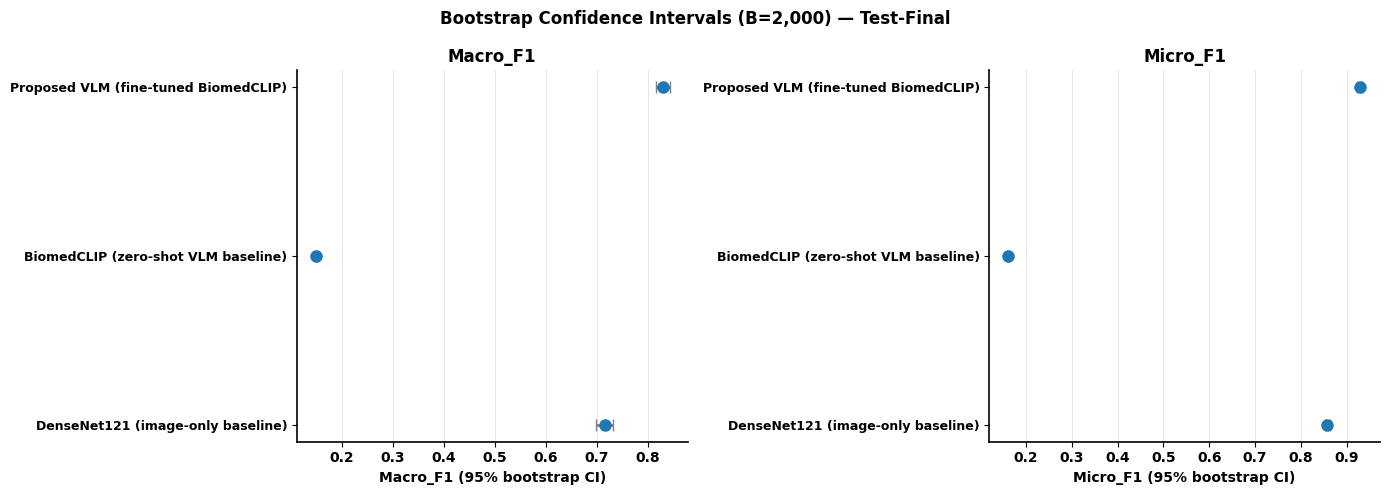

Saved: /content/drive/MyDrive/ROCOv2/Prepared/StatisticalAnalysis/figures/bootstrap_forest_plot.pdf
Saved: /content/drive/MyDrive/ROCOv2/Prepared/StatisticalAnalysis/figures/bootstrap_forest_plot_300dpi.png


In [ ]:
# ============================================================
# CELL 9 — FOREST PLOT FIGURE
# ============================================================

import matplotlib.pyplot as plt

plt.rcParams.update({
    "font.weight": "bold", "axes.labelweight": "bold", "axes.titleweight": "bold",
    "figure.facecolor": "white", "axes.facecolor": "white", "savefig.facecolor": "white",
    "font.size": 10, "axes.linewidth": 1.2,
})

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, metric_name in zip(axes, ["Macro_F1", "Micro_F1"]):
    subset = ci_df.loc[ci_df["Metric"] == metric_name].reset_index(drop=True)
    y_positions = np.arange(len(subset))
    errors = np.abs(subset[["CI_Lower", "CI_Upper"]].to_numpy().T - subset["Point_Estimate"].to_numpy())
    ax.errorbar(subset["Point_Estimate"], y_positions, xerr=errors, fmt="o", markersize=8,
                color="#1f77b4", ecolor="gray", capsize=4, linewidth=2)
    ax.set_yticks(y_positions)
    ax.set_yticklabels(subset["Model"], fontsize=9)
    ax.set_xlabel(f"{metric_name} ({CI_LEVEL:.0%} bootstrap CI)")
    ax.set_title(metric_name, fontweight="bold")
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.grid(alpha=0.3, axis="x")

fig.suptitle(f"Bootstrap Confidence Intervals (B={N_BOOTSTRAP:,}) — Test-Final", fontweight="bold")
fig.tight_layout()
fig.savefig(FOREST_FIGURE_PDF, format="pdf", bbox_inches="tight")
fig.savefig(FOREST_FIGURE_PNG, format="png", dpi=300, bbox_inches="tight")
plt.show()

print("Saved:", FOREST_FIGURE_PDF)
print("Saved:", FOREST_FIGURE_PNG)


## 9. Save configuration and reproducibility record

In [ ]:
# ============================================================
# CELL 10 — SAVE CONFIG AND REPRODUCIBILITY.JSON
# ============================================================

stats_config = {
    "method": "Paired bootstrap resampling (sample-level) + per-label paired Wilcoxon signed-rank test",
    "n_bootstrap": N_BOOTSTRAP, "ci_level": CI_LEVEL, "seed": SEED,
    "significance_criterion": "95% bootstrap CI of paired difference excludes zero",
    "models_compared": [m["display_name"] for m in MODEL_REGISTRY],
    "n_test_final_samples": N, "n_labels": N_LABELS,
}
safe_save_json(STATS_CONFIG_PATH, stats_config)

def package_version(module_name):
    try:
        module = __import__(module_name)
        return getattr(module, "__version__", "unknown")
    except Exception:
        return "not installed"

reproducibility = {
    "notebook": "13_ROCOv2_Statistical_Analysis",
    "python_version": sys.version, "platform": platform.platform(),
    "numpy_version": np.__version__, "pandas_version": pd.__version__,
    "scipy_version": package_version("scipy"), "sklearn_version": package_version("sklearn"),
    "random_seed": SEED, "n_bootstrap": N_BOOTSTRAP,
}
safe_save_json(REPRODUCIBILITY_PATH, reproducibility)


Saved: /content/drive/MyDrive/ROCOv2/Prepared/StatisticalAnalysis/statistical_analysis_config.json
Saved: /content/drive/MyDrive/ROCOv2/Prepared/StatisticalAnalysis/reproducibility.json


## 10. Artifact manifest and final report

In [ ]:
# ============================================================
# CELL 11 — ARTIFACT MANIFEST + FINAL REPORT
# ============================================================

artifact_paths = [
    CI_TABLE_PATH, PAIRWISE_TABLE_PATH, WILCOXON_TABLE_PATH,
    FOREST_FIGURE_PDF, FOREST_FIGURE_PNG, STATS_CONFIG_PATH, REPRODUCIBILITY_PATH,
]
manifest = [{
    "Artifact": p.name, "Path": str(p), "Exists": p.exists(),
    "Size_KB": round(p.stat().st_size / 1024, 2) if p.exists() else None,
} for p in artifact_paths]
artifact_manifest_df = pd.DataFrame(manifest)
display(artifact_manifest_df)

manifest_missing = [m["Path"] for m in manifest if not m["Exists"]]
notebook_status = "COMPLETE" if not manifest_missing else f"NOT READY — missing: {manifest_missing}"
safe_save_json(MANIFEST_PATH, {"artifacts": manifest, "status": notebook_status})

vlm_row = pairwise_df.loc[
    (pairwise_df["Model_A"].str.contains("Proposed")) & (pairwise_df["Metric"] == "Macro_F1")
]

print("\n" + "=" * 60)
print("ROCOv2 STATISTICAL ANALYSIS")
print("FINAL REPORT")
print("=" * 60)
print(f'''
Models compared:
{", ".join(m["display_name"] for m in MODEL_REGISTRY)}

Bootstrap iterations:
{N_BOOTSTRAP:,} (paired, seed={SEED})

------------------------------------------------------------
PAIRWISE SIGNIFICANCE (Macro-F1, Proposed VLM vs. each baseline)
------------------------------------------------------------
''')
display(vlm_row[["Model_A", "Model_B", "Mean_Difference_A_minus_B", "CI_Lower", "CI_Upper",
                  "Bootstrap_P_Value", "Significant_at_0.05"]])

print(f'''
------------------------------------------------------------
NOTEBOOK STATUS
------------------------------------------------------------

Statistical analysis implemented:
YES (paired bootstrap CI + significance, per-label Wilcoxon)

Model re-trained or re-run:
NO — purely derived from existing predictions

Previous notebooks modified:
NO

Pipeline status:
This is the final notebook (13 of 13).
''')
print("=" * 60)

if notebook_status != "COMPLETE":
    print("\nNOTEBOOK 13 STATUS: NOT READY — see missing artifacts above.")
else:
    print("\nSTOP — Notebook 13 (Statistical Analysis) is complete.")
    print("This is the final notebook in the ROCOv2 thesis pipeline.")


,Artifact,Path,Exists,Size_KB
0,bootstrap_confidence_intervals.csv,/content/drive/MyDrive/ROCOv2/Prepared/Statist...,True,0.68
1,pairwise_significance.csv,/content/drive/MyDrive/ROCOv2/Prepared/Statist...,True,0.97
2,per_label_wilcoxon.csv,/content/drive/MyDrive/ROCOv2/Prepared/Statist...,True,0.50
3,bootstrap_forest_plot.pdf,/content/drive/MyDrive/ROCOv2/Prepared/Statist...,True,19.40
4,bootstrap_forest_plot_300dpi.png,/content/drive/MyDrive/ROCOv2/Prepared/Statist...,True,139.68
5,statistical_analysis_config.json,/content/drive/MyDrive/ROCOv2/Prepared/Statist...,True,0.44
6,reproducibility.json,/content/drive/MyDrive/ROCOv2/Prepared/Statist...,True,0.33


Saved: /content/drive/MyDrive/ROCOv2/Prepared/StatisticalAnalysis/artifact_manifest.json

ROCOv2 STATISTICAL ANALYSIS
FINAL REPORT

Models compared:
DenseNet121 (image-only baseline), BiomedCLIP (zero-shot VLM baseline), Proposed VLM (fine-tuned BiomedCLIP)

Bootstrap iterations:
2,000 (paired, seed=42)

------------------------------------------------------------
PAIRWISE SIGNIFICANCE (Macro-F1, Proposed VLM vs. each baseline)
------------------------------------------------------------



,Model_A,Model_B,Mean_Difference_A_minus_B,CI_Lower,CI_Upper,Bootstrap_P_Value,Significant_at_0.05



------------------------------------------------------------
NOTEBOOK STATUS
------------------------------------------------------------

Statistical analysis implemented:
YES (paired bootstrap CI + significance, per-label Wilcoxon)

Model re-trained or re-run:
NO — purely derived from existing predictions

Previous notebooks modified:
NO

Pipeline status:
This is the final notebook (13 of 13).


STOP — Notebook 13 (Statistical Analysis) is complete.
This is the final notebook in the ROCOv2 thesis pipeline.
